# Lab 2 v2 — Executable Report: Oxford-IIIT Pets (`ResNet18`, `DenseNet121`, `VGG16`)

**Vai trò của Notebook:** Đây là **Executable Report** trình bày trực quan toàn bộ kết quả do bộ CLI scripts (`labs/lab2_v2/{prepare_data,train,evaluate,inference}.py`) tạo ra tại `experiments/lab2_v2/`, kèm kiểm chứng trực tiếp **Tensor Shapes**, **Freeze/Unfreeze Parameter Counts**, **Sanity Check** và **Live Top-5 Inference**.

> **Lưu ý vận hành:** Quá trình training thật chạy qua CLI (`python labs/lab2_v2/train.py --run-all --amp`) để có `tqdm` progress bar log, TensorBoard logs và tái lập sạch; notebook này **không train lại** 9 runs.

## Roadmap & Tài Liệu Liên Quan

- Đặc tả Pipeline 10 tầng: [`docs/pipelines/modeling.md`](docs/pipelines/modeling.md)
- Đặc tả 3 kiến trúc: [`docs/models/resnet18.md`](docs/models/resnet18.md) · [`docs/models/densenet121.md`](docs/models/densenet121.md) · [`docs/models/vgg16.md`](docs/models/vgg16.md)
- Báo cáo Dữ liệu & EDA (Layer 6): [`docs/eda_report.md`](docs/eda_report.md)
- Báo cáo Thí nghiệm & Training Diagnostics (Layer 4, 7): [`docs/experiment_report.md`](docs/experiment_report.md)
- Báo cáo Đánh giá Val/Test, Error Analysis 4 bước & Inference (Layer 8–10): [`docs/evaluation_report.md`](docs/evaluation_report.md)

In [1]:
import json, sys
from pathlib import Path
import pandas as pd
from IPython.display import display, Image as IPyImage

REPO_ROOT = Path.cwd().resolve()
if not (REPO_ROOT / 'labs' / 'lab2_v2').exists():
    REPO_ROOT = REPO_ROOT.parents[1]
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

import labs.lab2_v2.config as cfg
from src.vibe_scripts.lab2_v2.models import build_model, count_parameters, trace_shapes

print(f'Repo Root : {REPO_ROOT}')
print(f'Device    : {cfg.DEVICE} | Seed: {cfg.SEED} | Output: {cfg.EXPERIMENT_DIR}')

for arch, mode in [('resnet18', 'scratch'), ('resnet18', 'transfer'), ('resnet18', 'finetune'), ('densenet121', 'transfer'), ('vgg16', 'transfer')]:
    m = build_model(arch=arch, mode=mode, num_classes=cfg.NUM_CLASSES, pretrained=False)
    c = count_parameters(m)
    print(f'\n=== {arch.upper()} ({mode}) | total={c["total"]:,} | trainable={c["trainable"]:,} ({c["trainable_pct"]:.2f}%) ===')
    for row in trace_shapes(m, input_shape=(2, 3, 224, 224)):
        print(f'  {row["stage"]:28s} -> shape={row["shape"]} ({row["dtype"]})')

Repo Root : D:\notworLe\Desktop\gitvanhub\Deeplearning-UTH
Device    : cuda | Seed: 248 | Output: D:\notworLe\Desktop\gitvanhub\Deeplearning-UTH\experiments\lab2_v2

=== RESNET18 (scratch) | total=11,195,493 | trainable=11,195,493 (100.00%) ===
  Input                        -> shape=[2, 3, 224, 224] (torch.float32)
  stem: maxpool                -> shape=[2, 64, 56, 56] (torch.float32)
  layer1                       -> shape=[2, 64, 56, 56] (torch.float32)
  layer2                       -> shape=[2, 128, 28, 28] (torch.float32)
  layer3                       -> shape=[2, 256, 14, 14] (torch.float32)
  layer4                       -> shape=[2, 512, 7, 7] (torch.float32)
  avgpool                      -> shape=[2, 512, 1, 1] (torch.float32)
  head: fc                     -> shape=[2, 37] (torch.float32)

=== RESNET18 (transfer) | total=11,195,493 | trainable=18,981 (0.17%) ===
  Input                        -> shape=[2, 3, 224, 224] (torch.float32)
  stem: maxpool                -> shap

--- collection_report.json ---
{'dataset_name': 'Oxford-IIIT Pets (torchvision.datasets.OxfordIIITPet)', 'pet_dir': 'D:\\notworLe\\Desktop\\gitvanhub\\Deeplearning-UTH\\data\\raw\\oxford-iiit-pet', 'manifest_present': True, 'manifest_files_checked': 1, 'manifest_mismatches': 0, 'manifest_checks': [{'file_name': 'oxford-iiit-pet.tar.gz', 'exists': True, 'expected_size': 811706944, 'actual_size': 811706944, 'sha256_match': True, 'passed': True}], 'raw_trainval_samples': 3680, 'raw_test_samples': 3669, 'total_samples': 7349, 'num_classes': 37, 'num_cat_breeds': 12, 'num_dog_breeds': 25}
--- cleaning_report.json ---
{'total_scanned': 7349, 'corrupt_count': 0, 'corrupt_files': [], 'invalid_label_count': 0, 'color_mode_counts': {'RGB': 7346, 'RGBA': 3}, 'non_rgb_count': 3, 'non_rgb_handling': "Mọi ảnh đều ép `.convert('RGB')` trong PetImageDataset và preprocess_image() nên không mất mẫu.", 'internal_exact_duplicates': {'train': 0, 'val': 0, 'test': 0}, 'cross_split_exact_duplicates': 0, 'cro

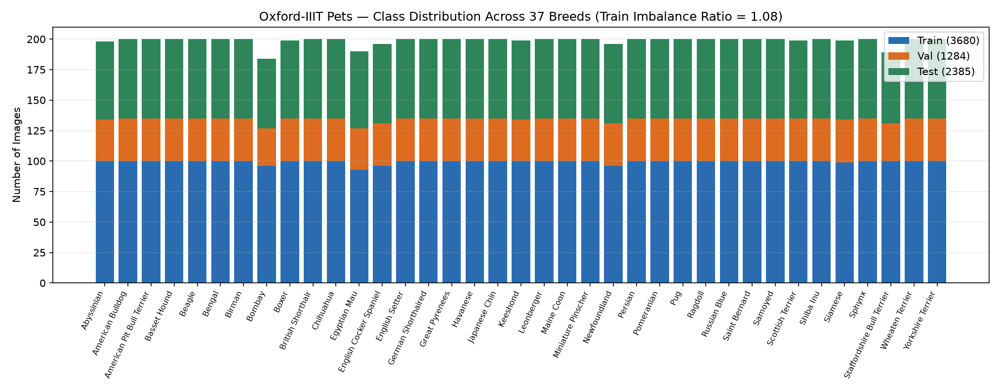

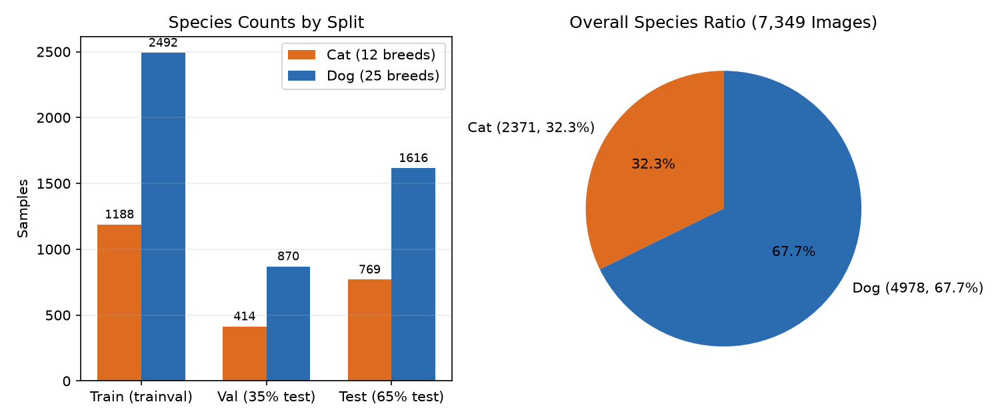

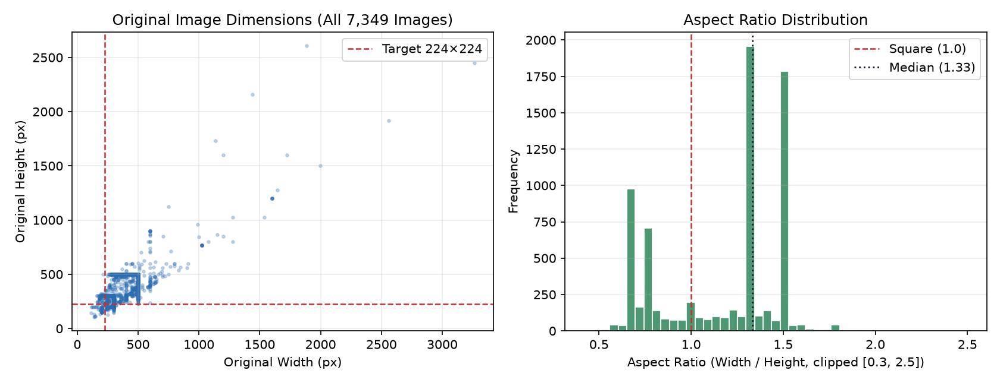

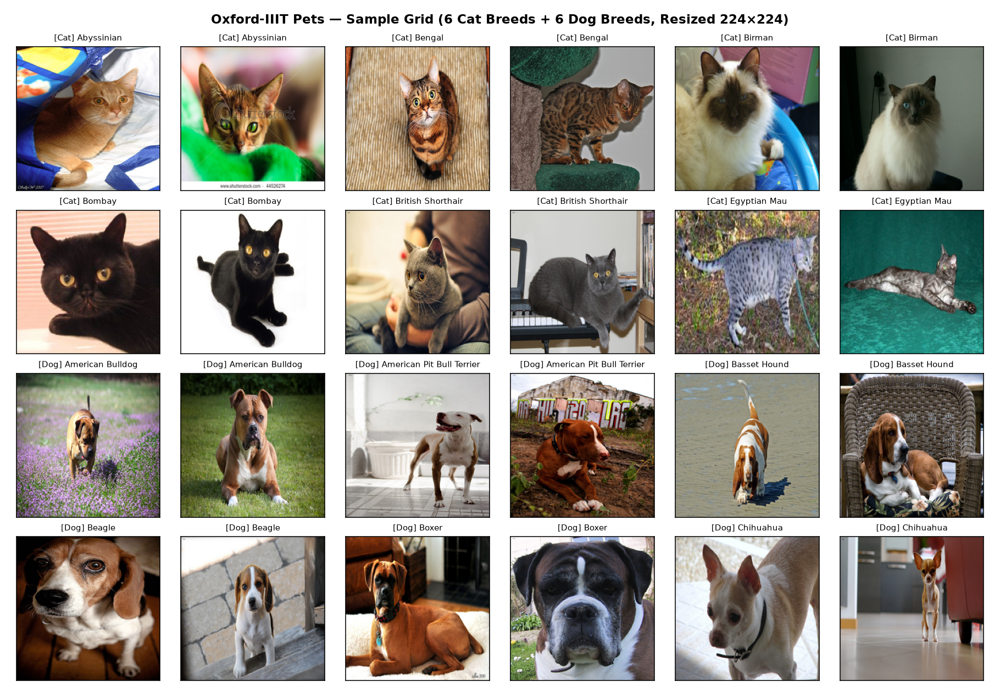

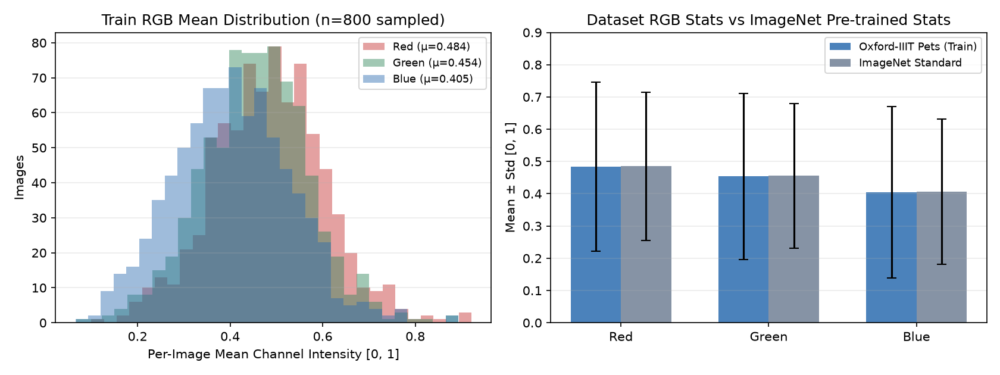

In [2]:
for name in ['collection_report.json', 'cleaning_report.json', 'eda_summary.json']:
    p = cfg.EDA_DIR / name
    if p.exists():
        print(f'--- {name} ---')
        data = json.loads(p.read_text(encoding='utf-8'))
        print({k: v for k, v in data.items() if k not in ('per_class_counts', 'cat_breeds', 'dog_breeds', 'non_rgb_samples')})

for fig_name in ['eda_class_distribution.png', 'eda_species_ratio.png', 'eda_size_aspect_ratio.png', 'eda_sample_grid.png', 'eda_rgb_stats.png']:
    fp = cfg.EDA_DIR / fig_name
    if fp.exists():
        display(IPyImage(filename=str(fp)))

Baseline: resnet18_scratch | Winner: densenet121_transfer


,run_id,group,axis,arch,mode,lr,lr_backbone,batch_size,epochs,total_params,trainable_params,trainable_pct,best_epoch,val_loss,val_acc,val_macro_f1,val_species_acc,train_time_sec,peak_vram_mb,save_load_passed
0,resnet18_scratch,Baseline (Scratch),baseline,resnet18,scratch,0.0010,0.0010,32,20,11195493,11195493,100.0000,19,1.810154,0.462617,0.456574,0.866822,589.167578,555.8,True
1,resnet18_transfer,Transfer Anchor,transfer_mode,resnet18,transfer,0.0010,0.0000,32,15,11195493,18981,0.1695,15,0.312524,0.900312,0.899283,0.991433,456.969129,182.6,True
2,resnet18_finetune,Fine-Tune (layer4),transfer_mode,resnet18,finetune,0.0010,0.0001,32,15,11195493,8412709,75.1437,10,0.298930,0.909657,0.908806,0.996106,484.923505,279.1,True
3,densenet121_transfer,Architecture Comparison,architecture,densenet121,transfer,0.0010,0.0000,32,15,6991781,37925,0.5424,14,0.240934,0.932243,0.931818,0.996106,423.632654,199.8,True
4,vgg16_transfer,Architecture Comparison,architecture,vgg16,transfer,0.0010,0.0000,32,15,134412133,151589,0.1128,13,0.276991,0.897196,0.895903,0.995327,624.153186,1317.9,True
5,resnet18_transfer_lr1e4,Ablation: Learning Rate,learning_rate,resnet18,transfer,0.0001,0.0000,32,15,11195493,18981,0.1695,15,0.821875,0.870717,0.868393,0.988318,542.453231,182.6,True
6,resnet18_transfer_lr5e3,Ablation: Learning Rate,learning_rate,resnet18,transfer,0.0050,0.0000,32,15,11195493,18981,0.1695,15,0.362881,0.890187,0.889378,0.993769,460.626843,182.6,True
7,resnet18_transfer_bs16,Ablation: Batch Size,batch_size,resnet18,transfer,0.0010,0.0000,16,15,11195493,18981,0.1695,15,0.309659,0.897196,0.896177,0.990654,347.875758,111.9,True
8,resnet18_transfer_bs64,Ablation: Batch Size,batch_size,resnet18,transfer,0.0010,0.0000,64,15,11195493,18981,0.1695,15,0.331130,0.900312,0.899089,0.992212,333.191260,318.7,True


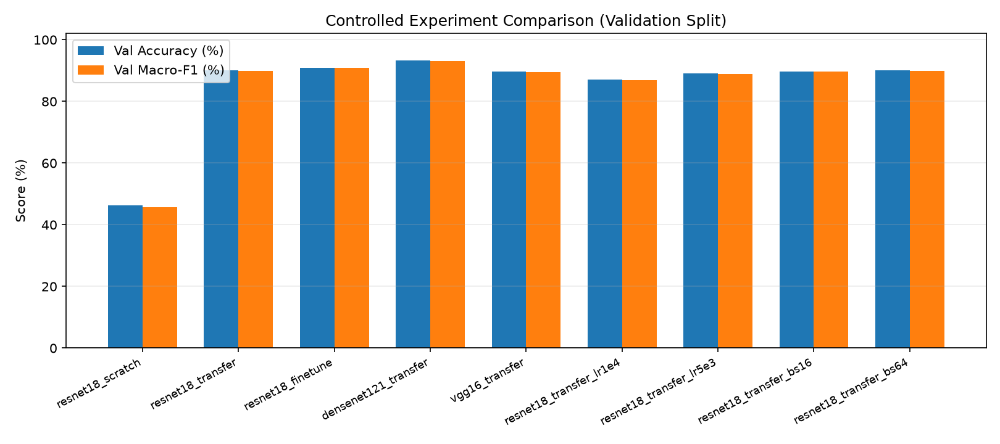

In [3]:
abl_csv = cfg.ABLATION_DIR / 'ablation_table.csv'
abl_json = cfg.ABLATION_DIR / 'ablation_summary.json'
if abl_csv.exists():
    df = pd.read_csv(abl_csv)
    display(df)
    summary = json.loads(abl_json.read_text(encoding='utf-8'))
    print('Baseline:', summary.get('baseline_run_id'), '| Winner:', summary.get('winning_model_run_id'))
    fig_p = cfg.FIGURES_DIR / 'ablation_comparison.png'
    if fig_p.exists():
        display(IPyImage(filename=str(fig_p)))
else:
    print('Chưa có ablation_table.csv — Kỹ sư cần chạy Step 6: python labs/lab2_v2/train.py --run-all --amp')

,run_id,arch,mode,total_params,trainable_params,test_loss,test_accuracy,test_macro_f1,species_accuracy,save_load_passed
0,resnet18_scratch,resnet18,scratch,11195493,11195493,1.764269,0.470860,0.462640,0.883438,True
1,densenet121_transfer,densenet121,transfer,6991781,37925,0.267812,0.919078,0.917553,0.997065,True


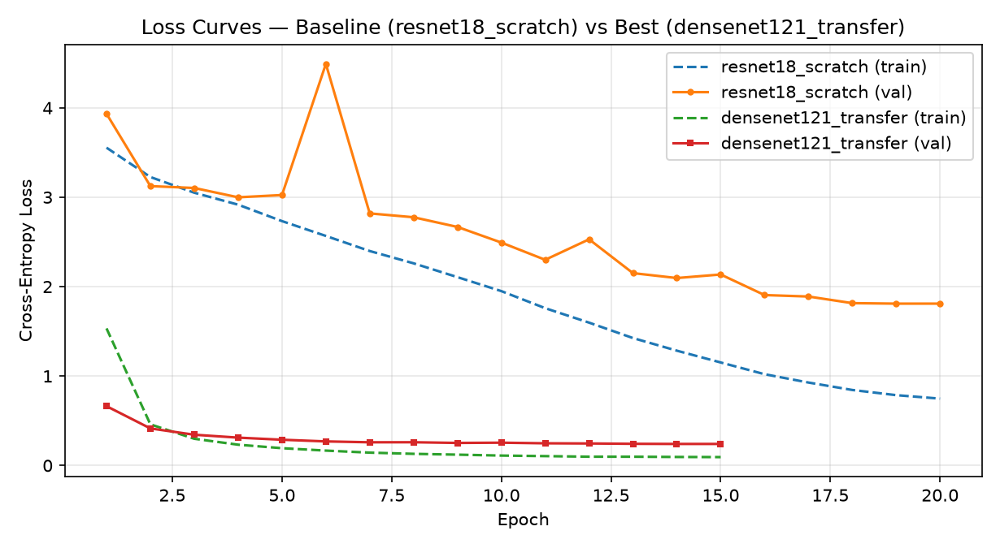

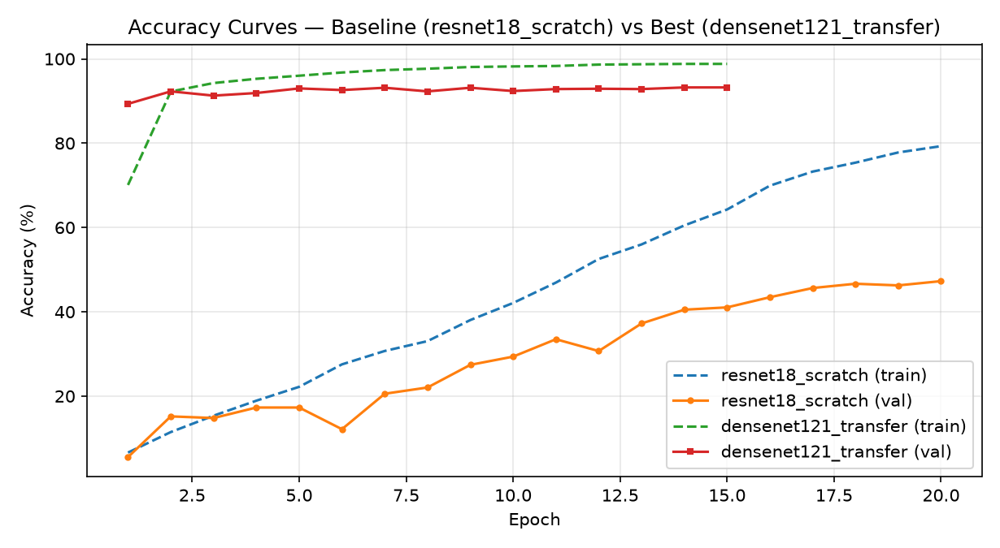

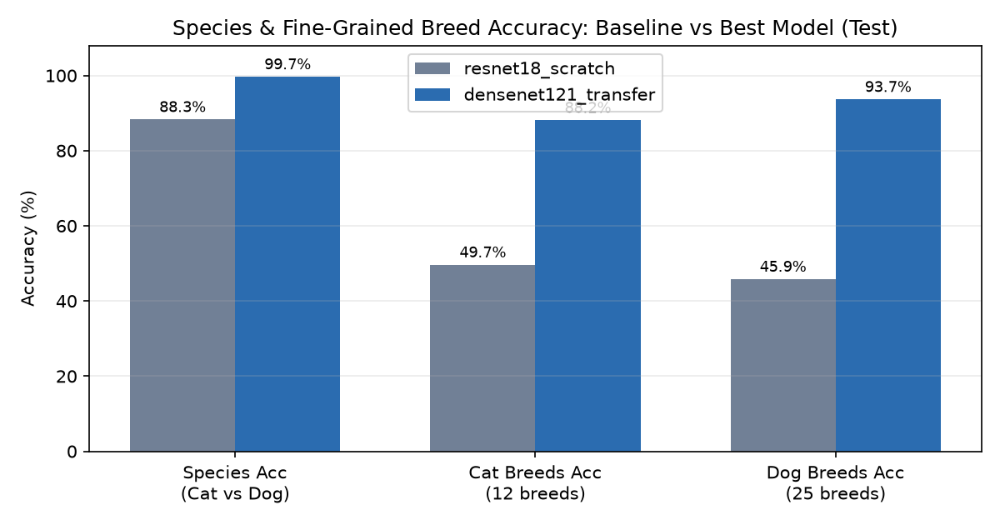

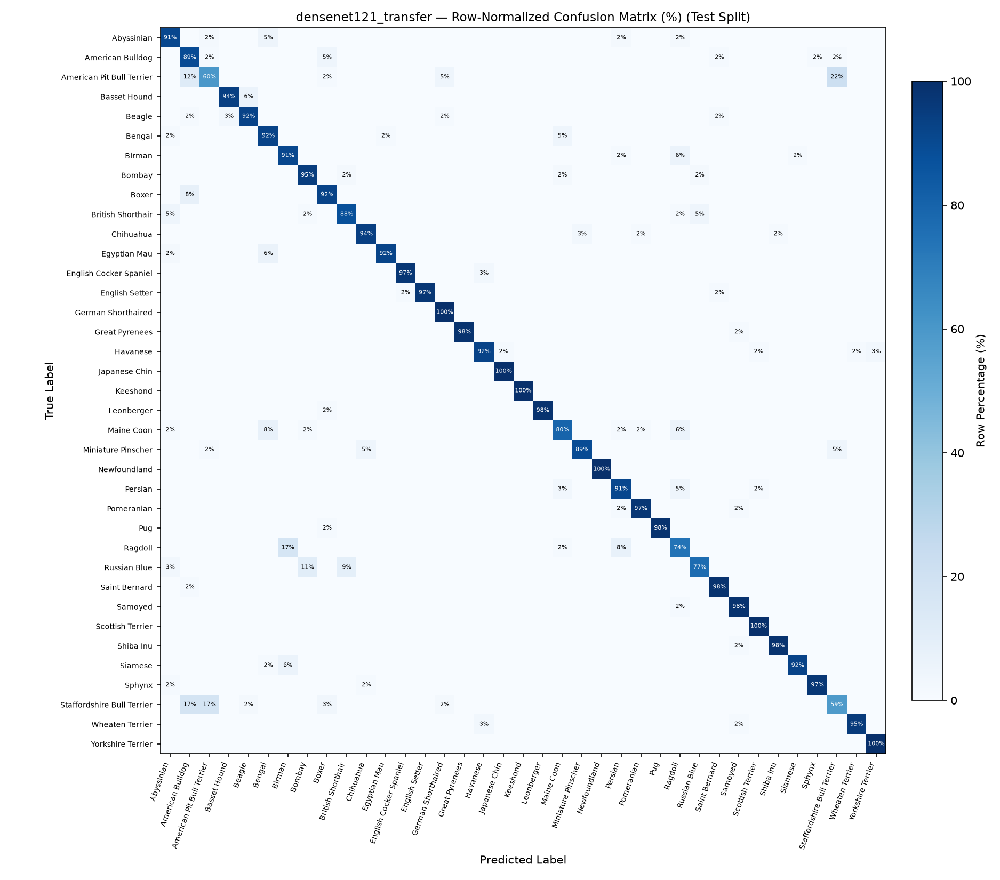

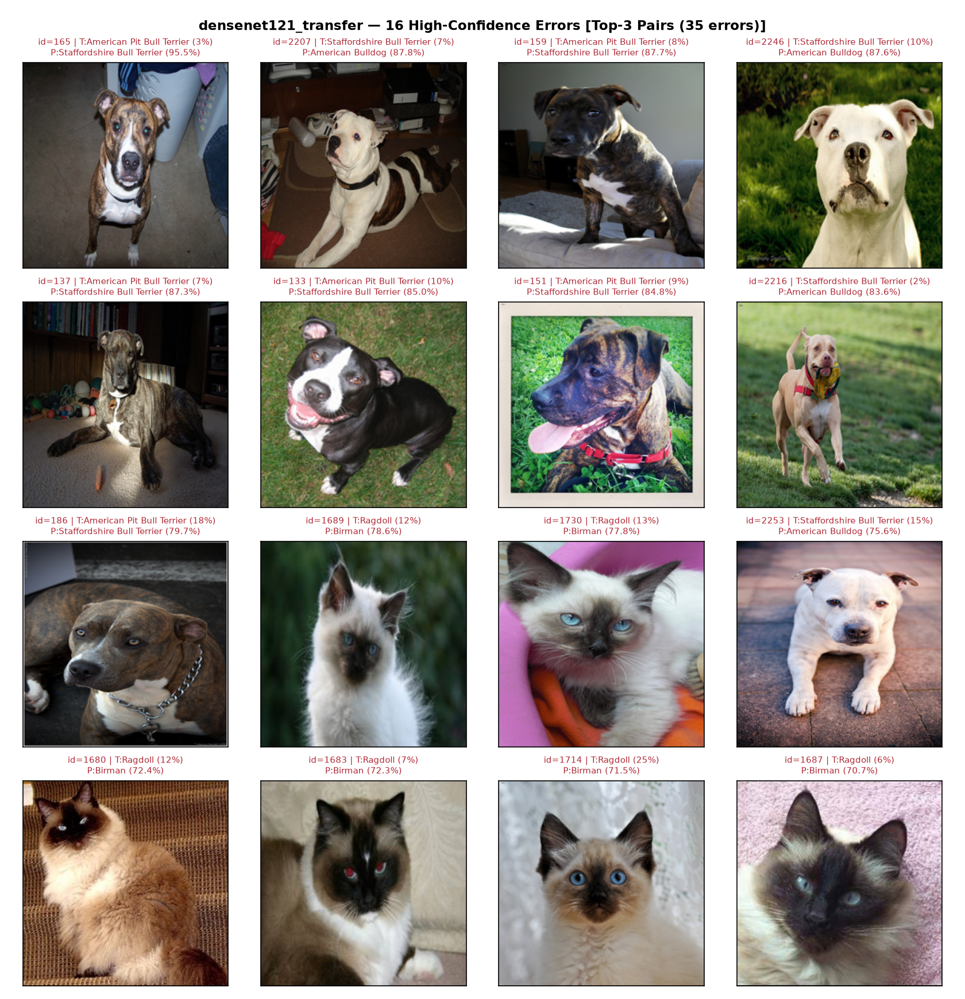

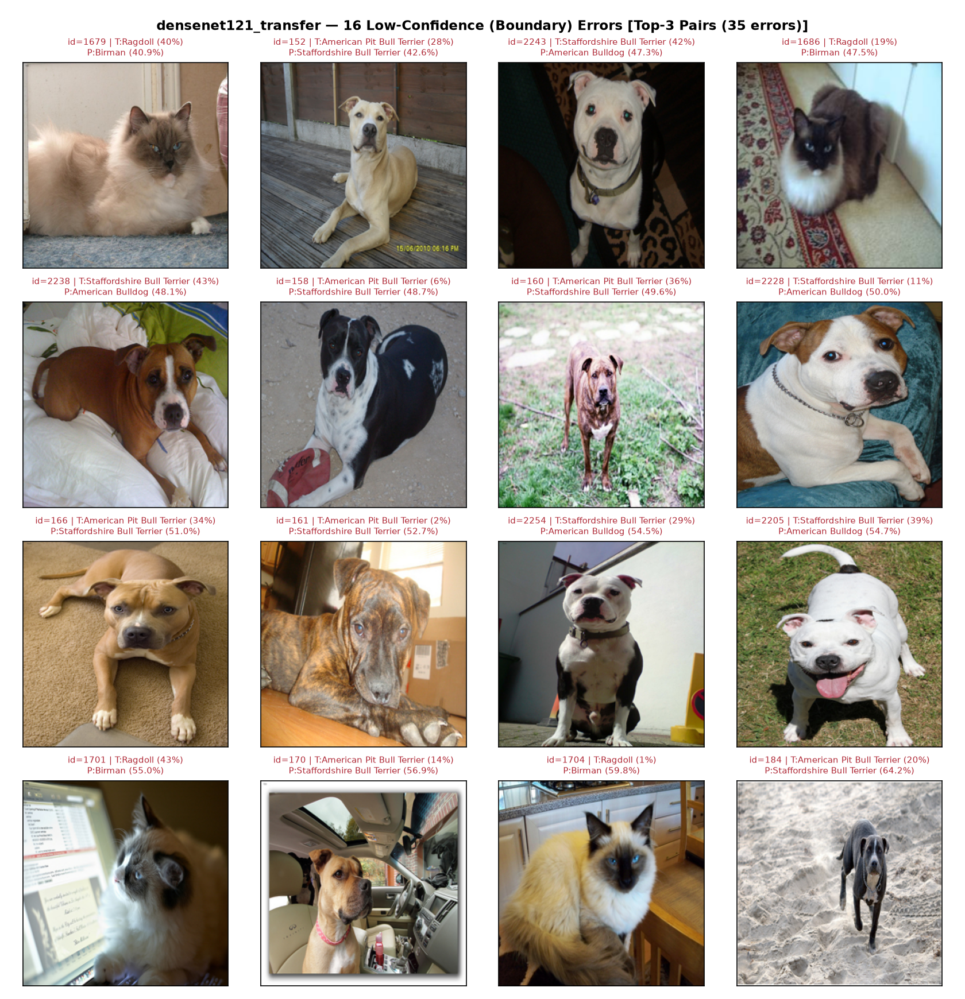

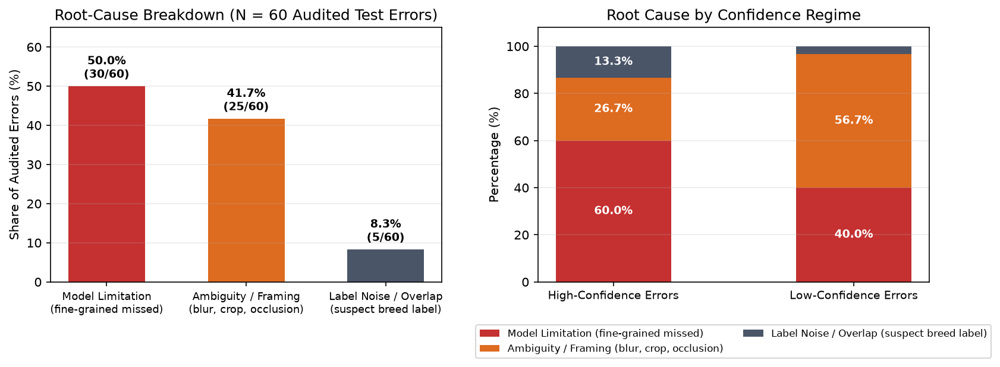

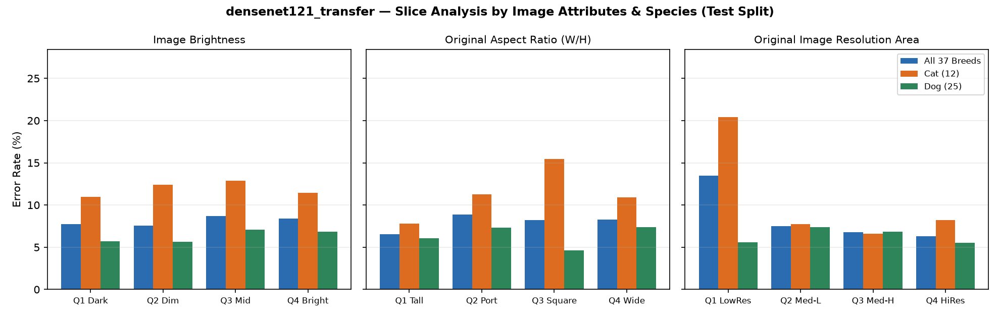

In [4]:
cmp_csv = cfg.EVALUATION_DIR / 'test_comparison.csv'
if cmp_csv.exists():
    display(pd.read_csv(cmp_csv))
    for fig_name in [
        'loss_curves.png',
        'accuracy_curves.png',
        'cat_vs_dog_error_comparison.png',
        'confusion_matrix_best_normalized.png',
        'error_gallery_top3_high_conf.png',
        'error_gallery_top3_low_conf.png',
        'error_taxonomy_breakdown.png',
        'error_slice_analysis.png',
    ]:
        fp = cfg.FIGURES_DIR / fig_name
        if fp.exists():
            display(IPyImage(filename=str(fp)))
else:
    print('Chưa có test_comparison.csv — Kỹ sư cần chạy Step 6 trước.')

In [5]:
from src.vibe_scripts.lab2_v2.data import prepare_oxford_pets
from src.vibe_scripts.lab2_v2.inference import PetPredictor

abl_json = cfg.ABLATION_DIR / 'ablation_summary.json'
if abl_json.exists():
    winner = json.loads(abl_json.read_text(encoding='utf-8')).get('winning_model_run_id')
    ckpt = cfg.RUNS_DIR / winner / 'best.pt'
    if ckpt.exists():
        bundle = prepare_oxford_pets(cfg.RAW_DATA_ROOT, batch_size=1, val_ratio_of_test=cfg.VAL_RATIO_OF_TEST, seed=cfg.SEED, split_file=cfg.SPLIT_FILE, download=False)
        pred = PetPredictor(ckpt, device=cfg.DEVICE)
        sample_path = bundle.image_paths['test'][0]
        true_name = bundle.class_names[bundle.labels['test'][0]]
        print('True:', true_name)
        print(json.dumps(pred.predict_image(sample_path, top_k=5), indent=2, ensure_ascii=False))
        print(json.dumps(pred.benchmark_latency(batch_sizes=(1, 32)), indent=2, ensure_ascii=False))
else:
    print('Chưa có checkpoint huấn luyện — bỏ qua live inference cho tới sau Step 6.')

True: Abyssinian
{
  "predicted_id": 0,
  "predicted_class": "Abyssinian",
  "species": "Cat",
  "confidence": 0.9765940308570862,
  "top_k": [
    {
      "class_id": 0,
      "class_name": "Abyssinian",
      "species": "Cat",
      "probability": 0.9765940308570862
    },
    {
      "class_id": 5,
      "class_name": "Bengal",
      "species": "Cat",
      "probability": 0.010027917101979256
    },
    {
      "class_id": 33,
      "class_name": "Sphynx",
      "species": "Cat",
      "probability": 0.003691858844831586
    },
    {
      "class_id": 10,
      "class_name": "Chihuahua",
      "species": "Dog",
      "probability": 0.002555409912019968
    },
    {
      "class_id": 11,
      "class_name": "Egyptian Mau",
      "species": "Cat",
      "probability": 0.001755683682858944
    }
  ],
  "requires_grad": false
}
{
  "checkpoint": "D:\\notworLe\\Desktop\\gitvanhub\\Deeplearning-UTH\\experiments\\lab2_v2\\runs\\densenet121_transfer\\best.pt",
  "checkpoint_size_mb": 27.55,